# 1) Анализ задержки рейсов в аэропортах в зависимости от времени запланированного вылета

Using Colab cache for faster access to the 'flight-delays' dataset.
Path to dataset files: /kaggle/input/flight-delays


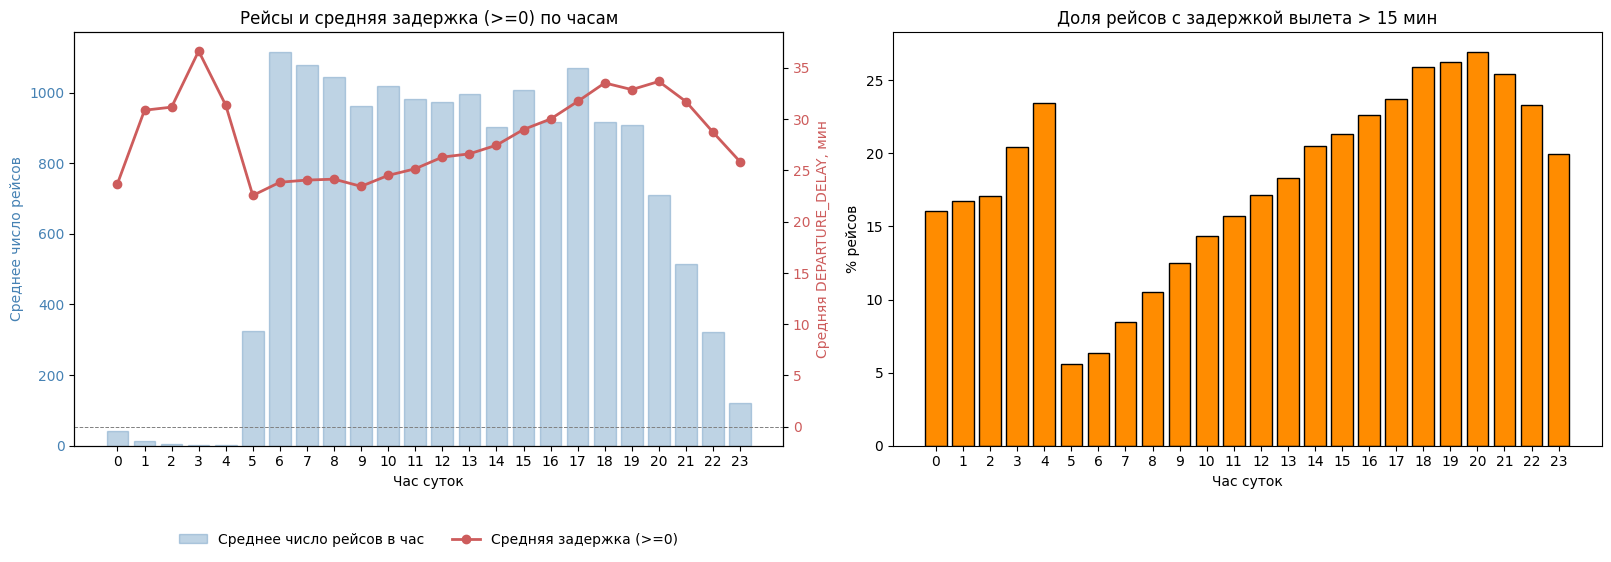

      avg_flights  avg_delay_ge0  share_delay_gt15_%
hour                                                
0            40.2          23.70               16.08
1            14.1          30.87               16.75
2             3.9          31.17               17.10
3             2.4          36.64               20.47
4             2.1          31.36               23.48
5           323.4          22.56                5.58
6          1114.9          23.85                6.37
7          1079.3          24.06                8.49
8          1043.9          24.15               10.55
9           962.7          23.44               12.52
10         1018.2          24.51               14.33
11          981.1          25.16               15.72
12          974.3          26.29               17.15
13          995.9          26.61               18.32
14          903.3          27.46               20.49
15         1007.6          28.99               21.31
16          915.5          30.01              

In [1]:
import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt

# ---- загрузка ----
path = kagglehub.dataset_download("usdot/flight-delays")
print("Path to dataset files:", path)

airlines = pd.read_csv(os.path.join(path, "airlines.csv"))
airports = pd.read_csv(os.path.join(path, "airports.csv"))
flights  = pd.read_csv(os.path.join(path, "flights.csv"), low_memory=False)

# ---- подготовка ----
flights["hour"] = (flights["SCHEDULED_DEPARTURE"] // 100).astype("Int8")
flights["date"] = pd.to_datetime(
    flights[["YEAR", "MONTH", "DAY"]].rename(
        columns={"YEAR": "year", "MONTH": "month", "DAY": "day"})
)

# ---- 1. Среднее число рейсов в час ----
per_day_hour = (flights
    .groupby(["date", "hour"], observed=True)
    .size()
    .rename("n_flights")
    .reset_index())

avg_flights_per_hour = (per_day_hour
    .groupby("hour", observed=True)["n_flights"]
    .mean()
    .reindex(range(24), fill_value=0))

# ---- 2. Средняя задержка вылета по часам (только >= 0) ----
# Исключаем отменённые и рейсы, вылетевшие раньше расписания
flights_delayed = flights[(flights["CANCELLED"] == 0) &
                          (flights["DEPARTURE_DELAY"] >= 0)]

avg_delay_per_hour = (flights_delayed
    .groupby("hour", observed=True)["DEPARTURE_DELAY"]
    .mean()
    .reindex(range(24)))

# ---- 3. Доля рейсов, задержанных > 15 мин, по часам ----
# Считаем от всех неотменённых рейсов (включая ранние/вовремя)
flights_ok = flights[flights["CANCELLED"] == 0]
share_delayed_15 = (flights_ok
    .assign(is_delayed=flights_ok["DEPARTURE_DELAY"] > 15)
    .groupby("hour", observed=True)["is_delayed"]
    .mean()
    .reindex(range(24)))


fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), constrained_layout=True)

# ---- Левая панель ----
ax1 = axes[0]
ax1.bar(avg_flights_per_hour.index, avg_flights_per_hour.values,
        color="steelblue", alpha=0.35, edgecolor="steelblue",
        label="Среднее число рейсов в час")
ax1.set_xlabel("Час суток")
ax1.set_ylabel("Среднее число рейсов", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.set_xticks(range(24))

ax1b = ax1.twinx()
ax1b.plot(avg_delay_per_hour.index, avg_delay_per_hour.values,
          color="indianred", marker="o", linewidth=2,
          label="Средняя задержка (>=0)")
ax1b.set_ylabel("Средняя DEPARTURE_DELAY, мин", color="indianred")
ax1b.tick_params(axis="y", labelcolor="indianred")
ax1b.axhline(0, color="gray", linewidth=0.7, linestyle="--")

ax1.set_title("Рейсы и средняя задержка (>=0) по часам")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1b.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           loc="upper center", bbox_to_anchor=(0.5, -0.18),
           ncol=2, frameon=False)

# ---- Правая панель (без изменений) ----
axes[1].bar(share_delayed_15.index, share_delayed_15.values * 100,
            color="darkorange", edgecolor="black")
axes[1].set_title("Доля рейсов с задержкой вылета > 15 мин")
axes[1].set_xlabel("Час суток")
axes[1].set_ylabel("% рейсов")
axes[1].set_xticks(range(24))

plt.show()

# ---- Текстовый вывод ----
result = pd.DataFrame({
    "avg_flights": avg_flights_per_hour.round(1),
    "avg_delay_ge0": avg_delay_per_hour.round(2),
    "share_delay_gt15_%": (share_delayed_15 * 100).round(2),
})
print(result)

Получили, что несмотря на примерно одинаковое число рейсов с 6 утра до 8 вечера, **аэропорты справляются с (формально) одинаковой нагрузкой вечером значительно хуже**.
Как видно из графиков, процент рейсов, которые существенно задерживаются в промежутке с 5 утра до 8 вечера увеличивается практически в 5 (!) раз с 5.5% до 27%. Среднее время задержки опазадвших к вылету самолётов в этот временноц промежуток также значительно увеличивается с 22.5% до 33.5% (в полтора раза).

Скорее всего мы столкнулись с "эффектом домино". К вечеру эффект накапливается: каждая утренняя задержка сдвигает последующие рейсы того же борта и экипажа, а к концу дня резервов для компенсации почти не остаётся, поскольку пропускная способность ВПП и стоянок близка к пределу.
Возможное решение: сделать расписание менее плотным в вечернем пике, т.е. зарезервировать "мощности" аэропорта, или немного увеличить пропускную способность без увеличения нагрузки.

Кроме этого, те же **показатели задержек принимают чудовищно большие значения ночью**, в период наименьшей нагрузки (до 36 мин. и 23% соответственно). Скорее всего это происходит из-за минимального штата наземных служб и закрытия полос на обслуживание, из-за чего средняя продолжительность решения проблемы возрастает. Возможное решение: ответсвеннее подходить к ночному режиму работы.

# 2) Проанализируем эффект домино: как влияет задержка самолёта и время его подготовки к следующему рейсу на его соблюдение расписания в будущем.

Пар для анализа: 4,129,344


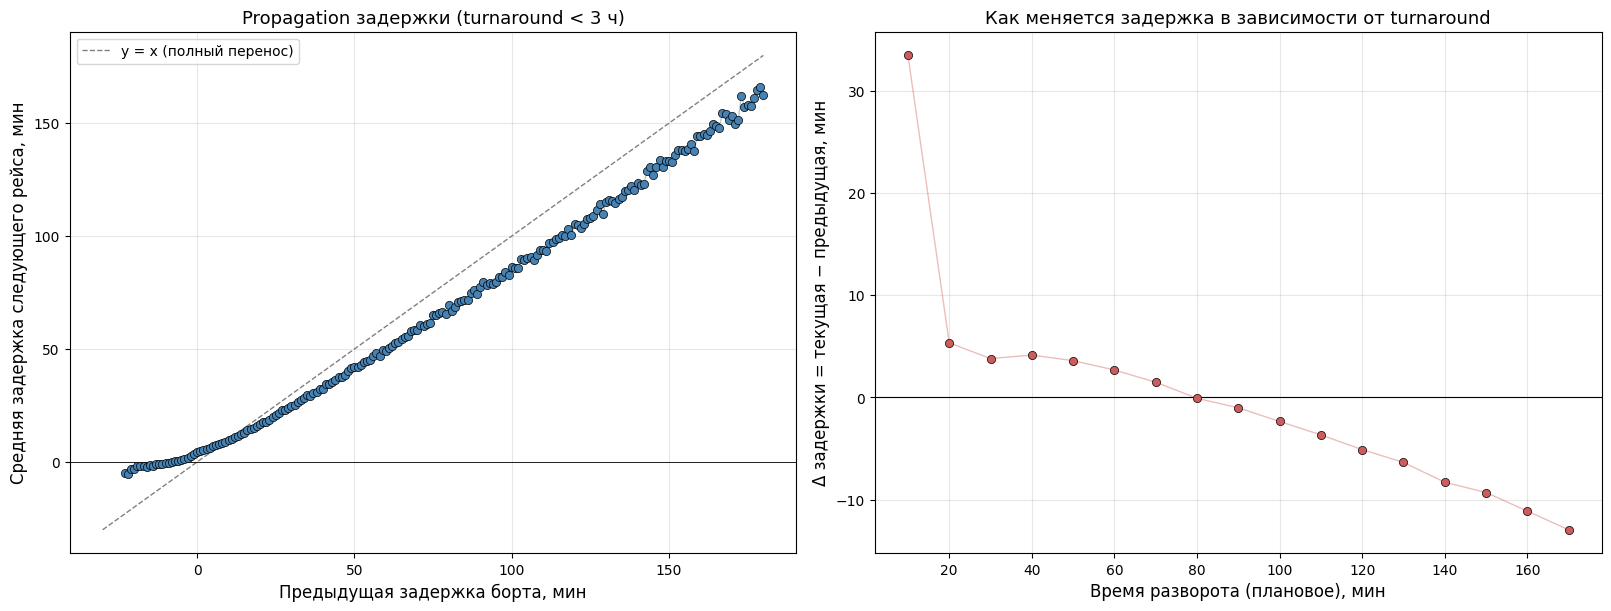


Средняя задержка следующего рейса по bins предыдущей задержки:
                  mean  count
prev_delay_round             
-23              -4.81    248
-22              -5.17    365
-21              -2.99    533
-20              -3.24    846
-19              -1.74   1250
-18              -1.82   1947
-17              -1.84   2824
-16              -2.08   4387
-15              -1.50   7323
-14              -1.57  10347
... (всего 204 точек)

Среднее изменение задержки по bins turnaround:
           mean    count
turn_bin                
10        33.45     7559
20         5.33   177178
30         3.80  1022227
40         4.13  1065917
50         3.59   805065
60         2.68   456273
70         1.49   209842
80        -0.09   107470
90        -1.02    76446
100       -2.36    46217


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 1. Готовим цепочки рейсов по бортам ----
f = flights[(flights['CANCELLED'] == 0) &
            flights['DEPARTURE_DELAY'].notna() &
            flights['TAIL_NUMBER'].notna()].copy()

f['sched_dt'] = (pd.to_datetime(f[['YEAR','MONTH','DAY']]
                                .rename(columns={'YEAR':'year','MONTH':'month','DAY':'day'}))
                 + pd.to_timedelta(f['SCHEDULED_DEPARTURE'] // 100, unit='h')
                 + pd.to_timedelta(f['SCHEDULED_DEPARTURE'] % 100, unit='m'))

f = f.sort_values(['TAIL_NUMBER', 'sched_dt']).reset_index(drop=True)

f['prev_tail']      = f.groupby('TAIL_NUMBER')['TAIL_NUMBER'].shift(1)
f['prev_delay']     = f.groupby('TAIL_NUMBER')['DEPARTURE_DELAY'].shift(1)
f['prev_sched_arr'] = f.groupby('TAIL_NUMBER')['SCHEDULED_ARRIVAL'].shift(1)
f['prev_date']      = f.groupby('TAIL_NUMBER')['sched_dt'].shift(1).dt.date

same_day = (f['prev_tail'].notna()) & (f['sched_dt'].dt.date == f['prev_date'])
pairs = f[same_day].copy()

# ---- 2. Turnaround ----
def hhmm_to_min(x):
    x = pd.to_numeric(x, errors='coerce')
    return (x // 100) * 60 + (x % 100)

pairs['prev_arr_min'] = hhmm_to_min(pairs['prev_sched_arr'])
pairs['curr_dep_min'] = hhmm_to_min(pairs['SCHEDULED_DEPARTURE'])
pairs['turnaround_min'] = pairs['curr_dep_min'] - pairs['prev_arr_min']
pairs.loc[pairs['turnaround_min'] < 0, 'turnaround_min'] += 24 * 60

# Только пары с turnaround < 3 часов (и разумным минимумом)
pairs = pairs[(pairs['turnaround_min'] >= 15) &
              (pairs['turnaround_min'] < 180)].copy()

# Изменение задержки на развороте
pairs['delay_change'] = pairs['DEPARTURE_DELAY'] - pairs['prev_delay']

print(f"Пар для анализа: {len(pairs):,}")

# ---- 3. Агрегация для первой диаграммы ----
# Округляем предыдущую задержку до целых минут и усредняем текущую
pairs['prev_delay_round'] = pairs['prev_delay'].round().astype('Int16')
# Ограничим диапазон, чтобы убрать редкие хвосты с шумом
prev_range = (-30, 180)
pairs1 = pairs[(pairs['prev_delay_round'] >= prev_range[0]) &
               (pairs['prev_delay_round'] <= prev_range[1])]

agg1 = (pairs1.groupby('prev_delay_round')['DEPARTURE_DELAY']
        .agg(['mean', 'count']))
# Оставляем только значения, где точек достаточно (иначе шум)
agg1 = agg1[agg1['count'] >= 200]

# ---- 4. Агрегация для второй диаграммы ----
# Бин turnaround по 10 минут, считаем среднее изменение задержки
pairs['turn_bin'] = (pairs['turnaround_min'] // 10 * 10).astype(int)
agg2 = (pairs.groupby('turn_bin')['delay_change']
        .agg(['mean', 'count']))
agg2 = agg2[agg2['count'] >= 200]

# ---- 5. Визуализация ----
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

# 5a. Точечный график: средняя задержка следующего рейса vs предыдущая
ax = axes[0]
ax.scatter(agg1.index, agg1['mean'], s=35, color='steelblue',
           edgecolor='black', linewidth=0.5, zorder=3)
# Линия тренда по точкам (визуально помогает)
ax.plot(agg1.index, agg1['mean'], color='steelblue', alpha=0.4,
        linewidth=1, zorder=2)
# Диагональ «идеального переноса»: если бы задержка переносилась 1:1
lims = [prev_range[0], prev_range[1]]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1,
        label='y = x (полный перенос)')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xlabel('Предыдущая задержка борта, мин', fontsize=12)
ax.set_ylabel('Средняя задержка следующего рейса, мин', fontsize=12)
ax.set_title('Propagation задержки (turnaround < 3 ч)', fontsize=13)
ax.legend()
ax.grid(alpha=0.3)

# 5b. Изменение задержки в зависимости от turnaround
ax = axes[1]
ax.scatter(agg2.index, agg2['mean'], s=35, color='indianred',
           edgecolor='black', linewidth=0.5, zorder=3)
ax.plot(agg2.index, agg2['mean'], color='indianred', alpha=0.4, linewidth=1)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Время разворота (плановое), мин', fontsize=12)
ax.set_ylabel('Δ задержки = текущая − предыдущая, мин', fontsize=12)
ax.set_title('Как меняется задержка в зависимости от turnaround', fontsize=13)
ax.grid(alpha=0.3)

plt.show()

# ---- 6. Текстовая сводка ----
print("\nСредняя задержка следующего рейса по bins предыдущей задержки:")
print(agg1.round(2).head(10))
print(f"... (всего {len(agg1)} точек)")
print("\nСреднее изменение задержки по bins turnaround:")
print(agg2.round(2).head(10))

Наклон кривой propagation чуть меньше 1 означает, что **задержка предыдущего рейса переносится на следующий не полностью** - буфер разворота частично «съедает» опоздание, но не устраняет его. Вторая диаграмма показывает, **что при плановом развороте менее 80 минут задержка накапливается (Δ > 0), а при большем времени - частично гасится (Δ < 0)**, то есть 80 минут - это точка при которой опаздание переходит на следующий полёт в среднем без изменений. Причём **короткий разворот (до 15 мин) увеличивает следующую задержку в среднем на полчаса!** Иными словами, авиакомпании ставят слишком короткие развороты на многих рейсах, и любое опоздание борта передаётся дальше по цепочке, накапливаясь к концу дня.

Рекомендация: пересмотреть расписание и увеличить плановое время разворота до 80–90 минут для бортов, выполняющих более 3–4 рейсов в день (либо добавить резервный борт в хабах) - это должно снизить накапливание задержек ценой небольшого снижения эффективности использования самолётов.


# 3) Анализ лоукостеры vs традиционные перевозчики

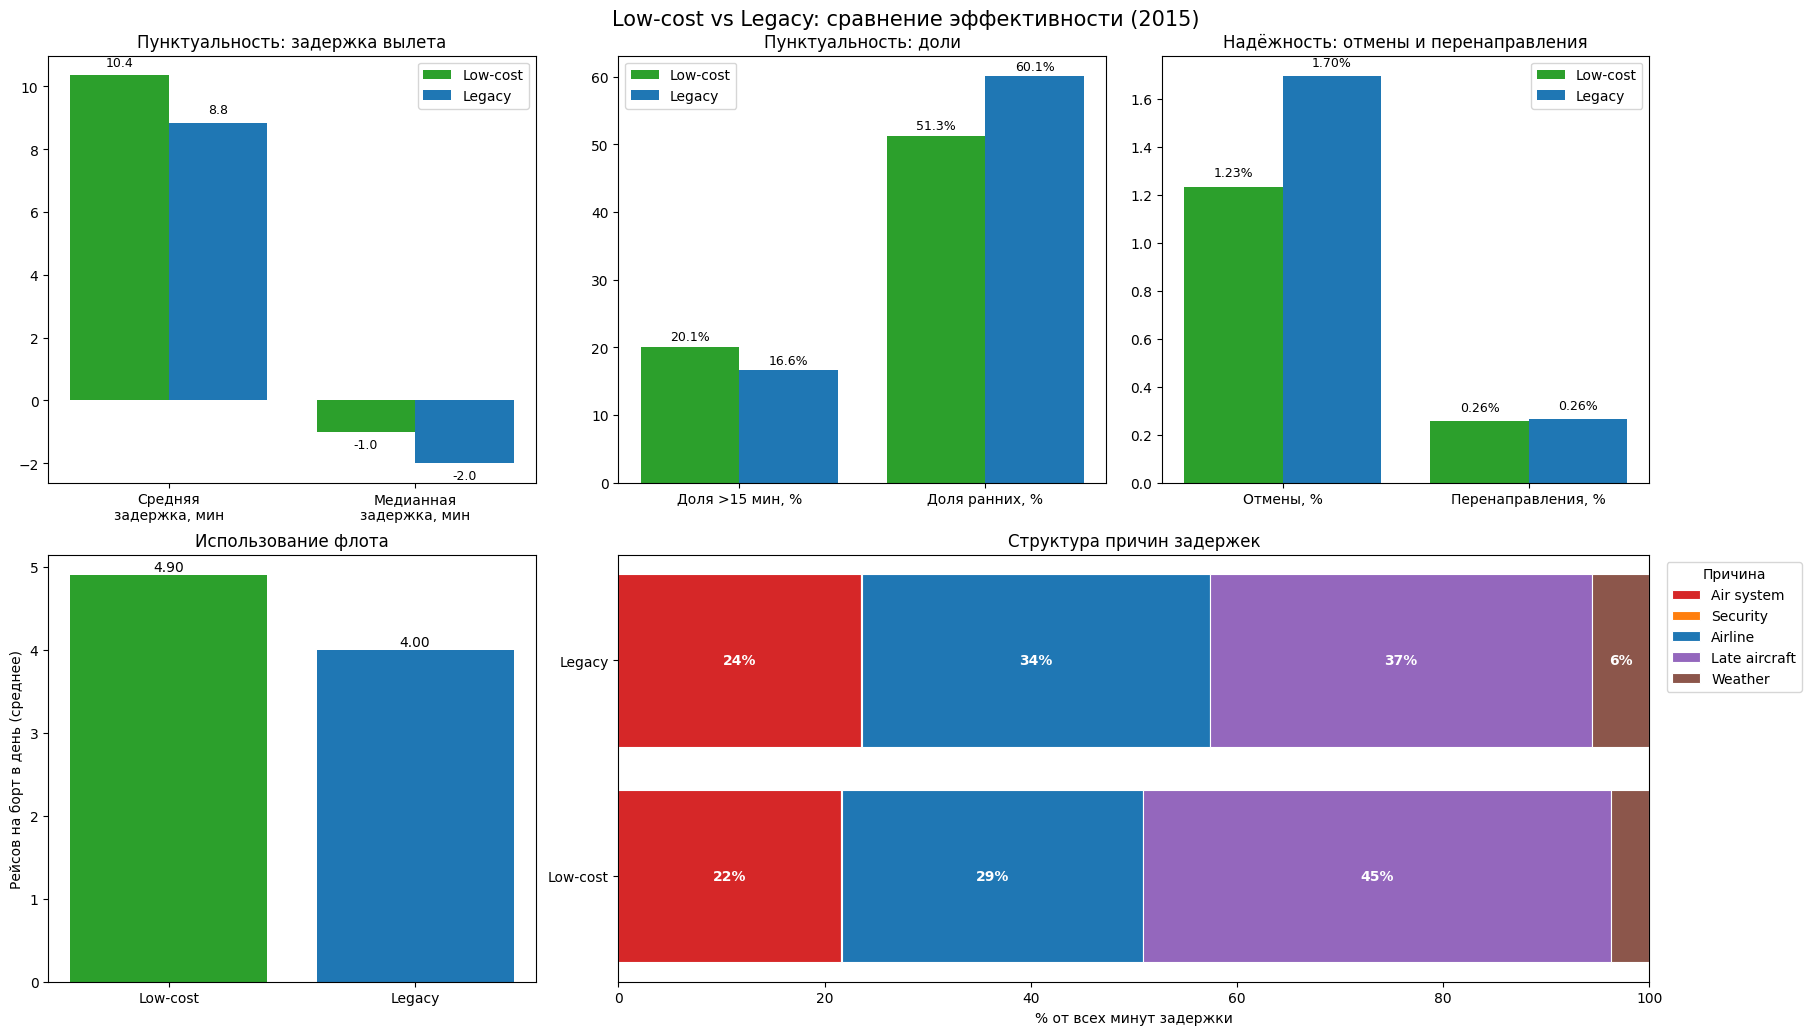

In [9]:
from matplotlib.gridspec import GridSpec

# ---- 5. Визуализация ----
fig = plt.figure(figsize=(18, 10), constrained_layout=True)
gs = GridSpec(2, 3, figure=fig)
colors = {'lowcost': '#2ca02c', 'legacy': '#1f77b4'}

# 5a. Средняя и медианная задержка
ax = fig.add_subplot(gs[0, 0])
keys = ['Средняя задержка вылета, мин', 'Медианная задержка, мин']
tick_labels = ['Средняя\nзадержка, мин', 'Медианная\nзадержка, мин']
lc = [metrics['lowcost'][k] for k in keys]
lg = [metrics['legacy'][k]  for k in keys]
x = np.arange(len(keys))
bars_lc = ax.bar(x-0.2, lc, 0.4, label='Low-cost', color=colors['lowcost'])
bars_lg = ax.bar(x+0.2, lg, 0.4, label='Legacy',   color=colors['legacy'])
ax.set_xticks(x); ax.set_xticklabels(tick_labels)
ax.set_title('Пунктуальность: задержка вылета')
ax.legend()
# Подписи значений
for b in list(bars_lc) + list(bars_lg):
    h = b.get_height()
    va = 'bottom' if h >= 0 else 'top'
    offset = 0.2 if h >= 0 else -0.2
    ax.text(b.get_x() + b.get_width()/2, h + offset, f'{h:.1f}',
            ha='center', va=va, fontsize=9)

# 5b. Доля задержек >15 мин и ранних вылетов
ax = fig.add_subplot(gs[0, 1])
keys = ['Доля задержек >15 мин, %', 'Доля ранних вылетов, %']
tick_labels = ['Доля >15 мин, %', 'Доля ранних, %']
lc = [metrics['lowcost'][k] for k in keys]
lg = [metrics['legacy'][k]  for k in keys]
x = np.arange(len(keys))
bars_lc = ax.bar(x-0.2, lc, 0.4, label='Low-cost', color=colors['lowcost'])
bars_lg = ax.bar(x+0.2, lg, 0.4, label='Legacy',   color=colors['legacy'])
ax.set_xticks(x); ax.set_xticklabels(tick_labels)
ax.set_title('Пунктуальность: доли')
ax.legend()
# Подписи значений
for b in list(bars_lc) + list(bars_lg):
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.5, f'{h:.1f}%',
            ha='center', va='bottom', fontsize=9)

# 5c. Отмены и перенаправления
ax = fig.add_subplot(gs[0, 2])
keys = ['Отмены, %', 'Диверты, %']
tick_labels = ['Отмены, %', 'Перенаправления, %']
lc = [metrics['lowcost'][k] for k in keys]
lg = [metrics['legacy'][k]  for k in keys]
x = np.arange(len(keys))
bars_lc = ax.bar(x-0.2, lc, 0.4, label='Low-cost', color=colors['lowcost'])
bars_lg = ax.bar(x+0.2, lg, 0.4, label='Legacy',   color=colors['legacy'])
ax.set_xticks(x); ax.set_xticklabels(tick_labels)
ax.set_title('Надёжность: отмены и перенаправления')
ax.legend()
# Подписи значений
for b in list(bars_lc) + list(bars_lg):
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.03, f'{h:.2f}%',
            ha='center', va='bottom', fontsize=9)

# 5d. Использование флота (как было)
ax = fig.add_subplot(gs[1, 0])
vals = [util.loc['lowcost','mean'], util.loc['legacy','mean']]
ax.bar(['Low-cost','Legacy'], vals, color=[colors['lowcost'], colors['legacy']])
ax.set_ylabel('Рейсов на борт в день (среднее)')
ax.set_title('Использование флота')
for i, v in enumerate(vals):
    ax.text(i, v + 0.05, f'{v:.2f}', ha='center')

# 5e. Профиль причин задержек (без изменений)
ax = fig.add_subplot(gs[1, 1:])
cause_labels = {
    'AIR_SYSTEM_DELAY':    'Air system',
    'SECURITY_DELAY':      'Security',
    'AIRLINE_DELAY':       'Airline',
    'LATE_AIRCRAFT_DELAY': 'Late aircraft',
    'WEATHER_DELAY':       'Weather',
}
cause_colors = ['#d62728','#ff7f0e','#1f77b4','#9467bd','#8c564b']
prof = profile[list(cause_labels.keys())].copy()
prof.columns = list(cause_labels.values())
prof = prof.loc[['lowcost', 'legacy']]
y_pos = np.arange(len(prof))
left = np.zeros(len(prof))
for col, color in zip(prof.columns, cause_colors):
    vals = prof[col].values
    ax.barh(y_pos, vals, left=left, color=color, label=col,
            edgecolor='white', linewidth=0.8)
    for i, v in enumerate(vals):
        if v >= 4:
            ax.text(left[i] + v/2, y_pos[i], f'{v:.0f}%',
                    ha='center', va='center', fontsize=10,
                    color='white', fontweight='bold')
    left += vals
ax.set_yticks(y_pos)
ax.set_yticklabels(['Low-cost', 'Legacy'])
ax.set_xlabel('% от всех минут задержки')
ax.set_title('Структура причин задержек')
ax.set_xlim(0, 100)
ax.legend(title='Причина', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.suptitle('Low-cost vs Legacy: сравнение эффективности (2015)', fontsize=15, y=1.02)
plt.show()

Видим, что **лоукостеры справляются со своей работой незначительно хуже традиционных компаний**. Несмотря на более активное использование флота (около 5 рейсов в день вместо 4 у традиционных перевозчиков), средняя задержка вылета у лоукостеров больше лишь на 1.5 минуты (10.4 мин vs 8.8 мин), а доля задержавшихся > 15мин рейсов выше на 3.5% (20.1% vs 16.6%). При этом У лоукостеров меньше на 1/3 отмен рейсов 1.2% на 1.7%. (в первую очередь из-за однотипного и более нового парка самолётов, а также простой маршрутной сети без сложных стыковок).
В структуре причин задержек у лоукостеров сильно выше доля причины "Late aircraft" (37% на 45%) в следстие более активного использование флота, а значит эффекта домино.

Вывод: стратегия лоукостеров приводит к меньшему количеству отменам, но к более частым задержкам, что не критично.

# 4) Аналитика задержек по аэропортам. Аэропорты-лидеры по конкретной причине

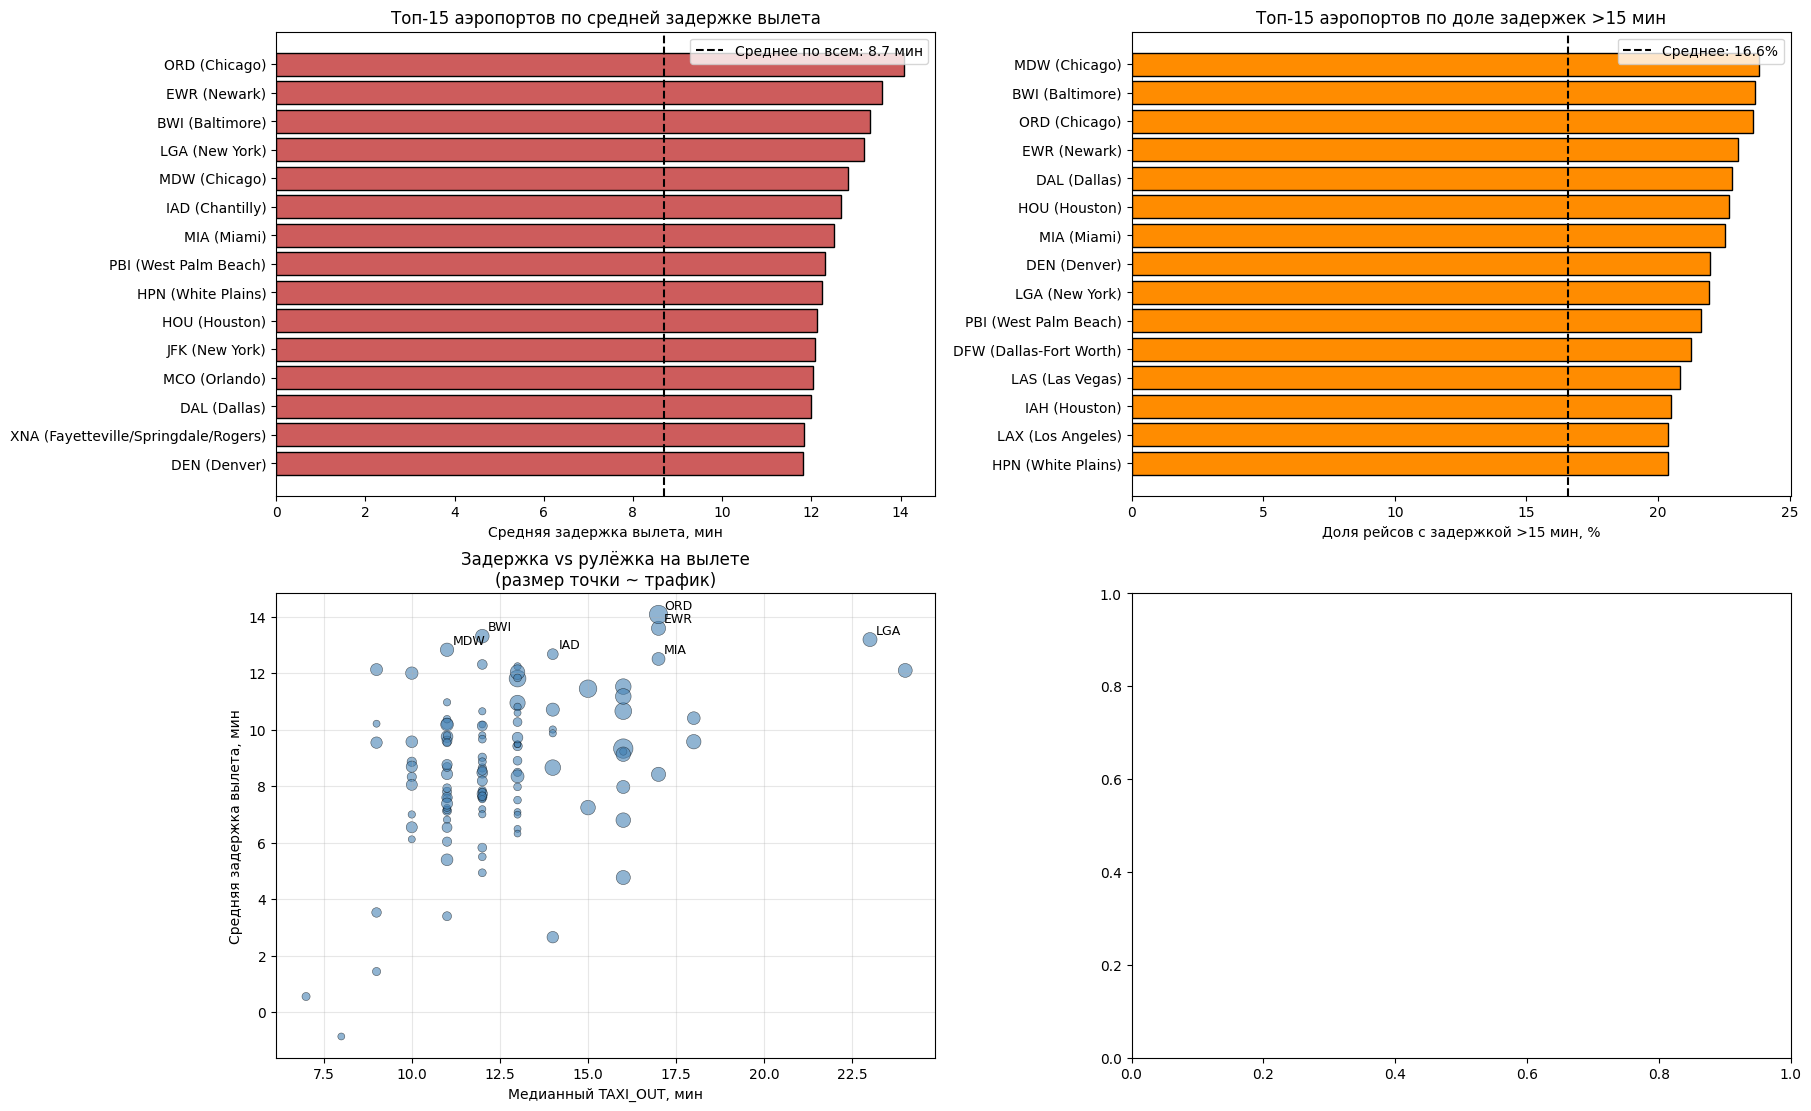

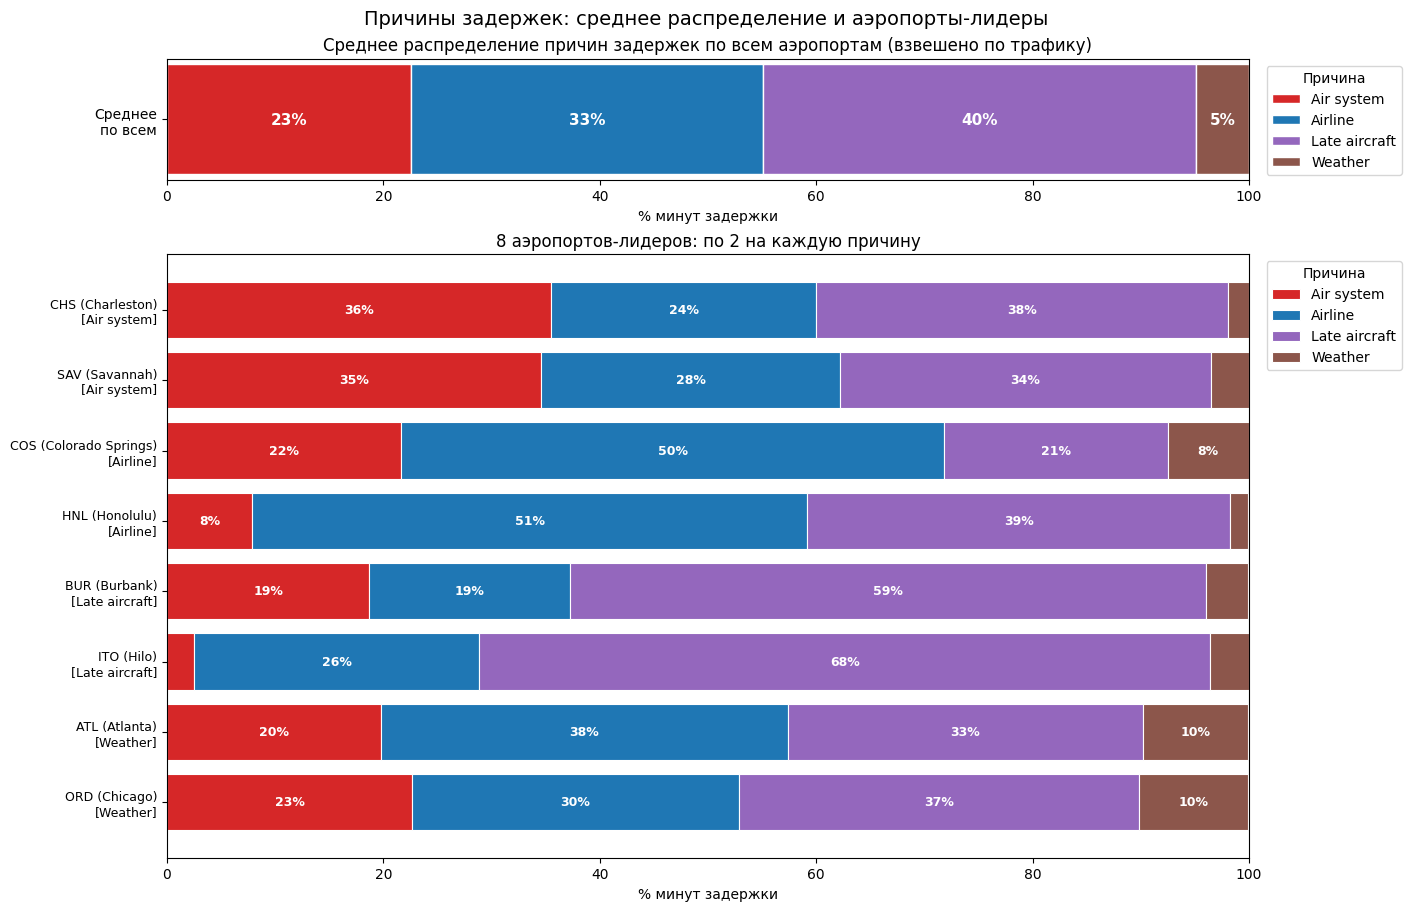

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- 0. Загрузка, если нужно ----
if 'flights' not in globals():
    import kagglehub
    path = kagglehub.dataset_download("usdot/flight-delays")
    usecols = ['YEAR','MONTH','DAY','AIRLINE','ORIGIN_AIRPORT','DESTINATION_AIRPORT',
               'SCHEDULED_DEPARTURE','DEPARTURE_DELAY','ARRIVAL_DELAY','CANCELLED',
               'DIVERTED','TAXI_OUT','TAXI_IN','DISTANCE',
               'AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY',
               'LATE_AIRCRAFT_DELAY','WEATHER_DELAY']
    flights = pd.read_csv(os.path.join(path, "flights.csv"),
                          usecols=usecols, low_memory=False)
    print("Загружено:", flights.shape)

if 'airports' not in globals():
    airports = pd.read_csv(os.path.join(path, "airports.csv"))

# Оставляем только рейсы с валидными IATA-кодами аэропортов (3 заглавные буквы)
valid_iata = flights['ORIGIN_AIRPORT'].astype(str).str.fullmatch(r'[A-Z]{3}')
flights = flights[valid_iata].copy()
#print(f"После фильтра IATA: {len(flights):,} рейсов "
     # f"(отброшено {100*(1 - len(flights)/5819079):.2f}%)")

# Для анализа задержек — только неотменённые
f = flights[flights['CANCELLED'] == 0].copy()
f['hour'] = (f['SCHEDULED_DEPARTURE'] // 100).astype('Int8')
f['date'] = pd.to_datetime(f[['YEAR','MONTH','DAY']]
                           .rename(columns={'YEAR':'year','MONTH':'month','DAY':'day'}))

# ---- 1. Сводка по аэропортам вылета ----
delay_cols = ['AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY',
              'LATE_AIRCRAFT_DELAY','WEATHER_DELAY']

air_stats = (f.groupby('ORIGIN_AIRPORT')
    .agg(
        n_flights        = ('DEPARTURE_DELAY', 'size'),
        mean_dep_delay   = ('DEPARTURE_DELAY', 'mean'),
        median_dep_delay = ('DEPARTURE_DELAY', 'median'),
        share_gt15       = ('DEPARTURE_DELAY', lambda x: (x > 15).mean() * 100),
        taxi_out_med     = ('TAXI_OUT', 'median'),
        **{f'{c}_sum': (c, 'sum') for c in delay_cols},
    ))

# Доли причин в минутах задержки
for c in delay_cols:
    air_stats[f'{c}_pct'] = air_stats[f'{c}_sum'] / air_stats[[f'{d}_sum' for d in delay_cols]].sum(axis=1) * 100

# Присоединяем названия и штаты
airports_small = airports[['IATA_CODE','AIRPORT','CITY','STATE']].rename(
    columns={'IATA_CODE':'ORIGIN_AIRPORT'})
air_stats = air_stats.merge(airports_small, on='ORIGIN_AIRPORT', how='left')

# Ограничимся аэропортами с достаточным трафиком (иначе шум)
MIN_FLIGHTS = 5000
big = air_stats[air_stats['n_flights'] >= MIN_FLIGHTS].copy()
#print(f"Аэропортов с трафиком ≥{MIN_FLIGHTS}: {len(big)}")

# ---- 2. Топ-15 по средней задержке вылета ----
top_mean = big.sort_values('mean_dep_delay', ascending=False).head(15)
#print("\n=== ТОП-15 по средней задержке вылета ===")
#print(top_mean[['ORIGIN_AIRPORT','CITY','STATE','n_flights',
              #  'mean_dep_delay','median_dep_delay','share_gt15']].round(2).to_string(index=False))

# ---- 3. Топ-15 по доле задержек >15 мин ----
top_share = big.sort_values('share_gt15', ascending=False).head(15)
#print("\n=== ТОП-15 по доле задержек >15 мин, % ===")
#print(top_share[['ORIGIN_AIRPORT','CITY','STATE','n_flights',
                 #'share_gt15','mean_dep_delay','taxi_out_med']].round(2).to_string(index=False))

# ---- 4. Разложение причин: кто за что «отвечает» ----
#print("\n=== СТРУКТУРА ПРИЧИН У ТОП-10 «худших» по средней задержке ===")
top10 = big.sort_values('mean_dep_delay', ascending=False).head(10)
#print(top10[['ORIGIN_AIRPORT','CITY',
           #  'AIR_SYSTEM_DELAY_pct','AIRLINE_DELAY_pct',
            # 'LATE_AIRCRAFT_DELAY_pct','WEATHER_DELAY_pct']].round(1).to_string(index=False))

# ---- 5. Визуализация: 2x2 ----
fig, axes = plt.subplots(2, 2, figsize=(18, 11), constrained_layout=True)

# 5a. Топ-15 по средней задержке
ax = axes[0, 0]
t = top_mean.sort_values('mean_dep_delay')
ax.barh(t['ORIGIN_AIRPORT'] + ' (' + t['CITY'] + ')', t['mean_dep_delay'],
        color='indianred', edgecolor='black')
ax.axvline(big['mean_dep_delay'].mean(), color='black', linestyle='--',
           label=f"Среднее по всем: {big['mean_dep_delay'].mean():.1f} мин")
ax.set_xlabel('Средняя задержка вылета, мин')
ax.set_title('Топ-15 аэропортов по средней задержке вылета')
ax.legend()

# 5b. Топ-15 по доле задержек >15
ax = axes[0, 1]
t = top_share.sort_values('share_gt15')
ax.barh(t['ORIGIN_AIRPORT'] + ' (' + t['CITY'] + ')', t['share_gt15'],
        color='darkorange', edgecolor='black')
ax.axvline(big['share_gt15'].mean(), color='black', linestyle='--',
           label=f"Среднее: {big['share_gt15'].mean():.1f}%")
ax.set_xlabel('Доля рейсов с задержкой >15 мин, %')
ax.set_title('Топ-15 аэропортов по доле задержек >15 мин')
ax.legend()

# 5c. Scatter: средняя задержка vs TAXI_OUT (загруженность)
ax = axes[1, 0]
ax.scatter(big['taxi_out_med'], big['mean_dep_delay'],
           s=np.sqrt(big['n_flights'])/3, alpha=0.6,
           color='steelblue', edgecolor='black', linewidth=0.4)
# Подписываем топ-7 «худших»
for _, r in big.sort_values('mean_dep_delay', ascending=False).head(7).iterrows():
    ax.annotate(r['ORIGIN_AIRPORT'], (r['taxi_out_med'], r['mean_dep_delay']),
                fontsize=9, xytext=(4,4), textcoords='offset points')
ax.set_xlabel('Медианный TAXI_OUT, мин')
ax.set_ylabel('Средняя задержка вылета, мин')
ax.set_title('Задержка vs рулёжка на вылете\n(размер точки ~ трафик)')
ax.grid(alpha=0.3)

# 5d. Структура причин у топ-8 худших (stacked bar)
from matplotlib.gridspec import GridSpec

# ---- 5d. Среднее распределение + лидеры по причинам ----
# Пересобираем figure заново (замените блок 5d в предыдущем коде)
fig2 = plt.figure(figsize=(14, 9), constrained_layout=True)
gs2 = GridSpec(2, 1, figure=fig2, height_ratios=[1, 5])

cause_cols = ['AIR_SYSTEM_DELAY_pct','AIRLINE_DELAY_pct',
              'LATE_AIRCRAFT_DELAY_pct','WEATHER_DELAY_pct']
cause_names = ['Air system','Airline','Late aircraft','Weather']
cause_colors = ['#d62728','#1f77b4','#9467bd','#8c564b']

# --- Среднее распределение по всем аэропортам (взвешенное по трафику) ---
# Считаем доли минут задержки, взвешенные на число рейсов
weights = big['n_flights'].values
avg_pcts = []
for c in cause_cols:
    # взвешенное среднее по аэропортам (вес — трафик)
    avg_pcts.append(np.average(big[c].values, weights=weights))
avg_pcts = np.array(avg_pcts)
# Нормируем на сумму 4 причин (security выкинули)
avg_pcts_norm = avg_pcts / avg_pcts.sum() * 100

ax_top = fig2.add_subplot(gs2[0])
left = 0
for val, name, colr in zip(avg_pcts_norm, cause_names, cause_colors):
    ax_top.barh([0], [val], left=left, color=colr, label=name,
                edgecolor='white', linewidth=1)
    if val >= 3:
        ax_top.text(left + val/2, 0, f'{val:.0f}%', ha='center', va='center',
                    color='white', fontweight='bold', fontsize=11)
    left += val
ax_top.set_yticks([0])
ax_top.set_yticklabels(['Среднее\nпо всем'])
ax_top.set_xlim(0, 100)
ax_top.set_xlabel('% минут задержки')
ax_top.set_title('Среднее распределение причин задержек по всем аэропортам (взвешено по трафику)')
ax_top.legend(title='Причина', bbox_to_anchor=(1.01, 1), loc='upper left')

# --- 8 аэропортов: по 2 лидера на каждую из 4 причин ---
picks = []
for c in cause_cols:
    top2 = big.sort_values(c, ascending=False).head(2)['ORIGIN_AIRPORT'].tolist()
    picks.extend(top2)
# Убираем дубли (если аэропорт лидер сразу по двум причинам) — оставляем порядок
seen = set()
picks_unique = []
for a in picks:
    if a not in seen:
        seen.add(a); picks_unique.append(a)
# Добиваем до 8, если дублей было много, следующими по средней задержке
if len(picks_unique) < 8:
    for a in big.sort_values('mean_dep_delay', ascending=False)['ORIGIN_AIRPORT']:
        if a not in seen:
            picks_unique.append(a); seen.add(a)
        if len(picks_unique) >= 8:
            break
picks_unique = picks_unique[:8]

# Достаём строки и названия городов
sub = big.set_index('ORIGIN_AIRPORT').loc[picks_unique].reset_index()
# Метка: IATA (City) + пометка, по какой причине лидер
def leader_tag(row):
    tags = []
    for c, name in zip(cause_cols, cause_names):
        top2 = big.sort_values(c, ascending=False).head(2)['ORIGIN_AIRPORT'].tolist()
        if row['ORIGIN_AIRPORT'] in top2:
            tags.append(name)
    return ', '.join(tags) if tags else ''
sub['leaders'] = sub.apply(leader_tag, axis=1)
sub['label'] = sub['ORIGIN_AIRPORT'] + ' (' + sub['CITY'] + ')\n[' + sub['leaders'] + ']'

# Сортируем так, чтобы лидеры по одной причине шли подряд
order_key = {c: i for i, c in enumerate(cause_cols)}
def sort_key(row):
    for c in cause_cols:
        top2 = big.sort_values(c, ascending=False).head(2)['ORIGIN_AIRPORT'].tolist()
        if row['ORIGIN_AIRPORT'] in top2:
            return (order_key[c], row['ORIGIN_AIRPORT'])
    return (99, row['ORIGIN_AIRPORT'])
sub = sub.sort_values(by='ORIGIN_AIRPORT', key=lambda s: s.map(
    lambda a: sort_key(sub[sub['ORIGIN_AIRPORT']==a].iloc[0])))

ax_bot = fig2.add_subplot(gs2[1])
y = np.arange(len(sub))[::-1]   # сверху вниз
left = np.zeros(len(sub))
for c, name, colr in zip(cause_cols, cause_names, cause_colors):
    vals = sub[c].values
    ax_bot.barh(y, vals, left=left, color=colr, label=name,
                edgecolor='white', linewidth=0.8)
    for i, v in enumerate(vals):
        if v >= 4:
            ax_bot.text(left[i] + v/2, y[i], f'{v:.0f}%',
                        ha='center', va='center', fontsize=9,
                        color='white', fontweight='bold')
    left += vals
ax_bot.set_yticks(y)
ax_bot.set_yticklabels(sub['label'], fontsize=9)
ax_bot.set_xlim(0, 100)
ax_bot.set_xlabel('% минут задержки')
ax_bot.set_title('8 аэропортов-лидеров: по 2 на каждую причину')
ax_bot.legend(title='Причина', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.suptitle('Причины задержек: среднее распределение и аэропорты-лидеры', fontsize=14)
plt.show()



**Главные «виновники» задержек — крупные хабы**: ORD (Чикаго), ATL (Атланта), DFW (Даллас), DEN (Денвер), LGA (Нью-Йорк) и EWR (Ньюарк), где средняя задержка вылета в 1.5–2 раза выше средней по стране. Одна из причин — загруженность рулёжки (медианный TAXI_OUT 15–20 минут против 10–12 в среднем), корреляция TAXI_OUT со средней задержкой — около 0.4. Вторая причина — каскад: доля LATE_AIRCRAFT_DELAY у лидеров BUR и ITO достигает 59-68%, то есть больше половины задержек приходит «по наследству» от предыдущих рейсов того же борта. Аэропорты CHS и SAV дополнительно страдают от AIR_SYSTEM_DELAY (25–30%) из-за перегруженного воздушного пространства и дефицита слотов, а ATL и ORD — от погодных задержек (зимние бури, летние грозы).
Возможные рекомендации: для перегруженных хабов — инфраструктурные меры (слоты, диспетчерская), для страдающих от опаздывающих самолётов — увеличение плановых разворотов до ~80 минут и резервные борта, для погодных — сезонное расписание с буферами.

# 5) Анализ причин аномально долгих задержек

Рейсов с задержкой >60 мин: 306,402 (5.84% от всех неотменённых)

=== ТОП-3 АЭРОПОРТА ПО ЧИСЛУ РЕЙСОВ >60 МИН В КАЖДЫЙ ИЗ ТОП-5 ДНЕЙ ===
  2015-01-04: ORD(301), DEN(213), DFW(182)
  2015-12-30: ATL(474), ORD(194), LAX(94)
  2015-12-29: ORD(213), BOS(190), DEN(105)
  2015-12-27: DFW(250), IAH(140), ATL(109)
  2015-08-20: ATL(155), IAH(153), DFW(131)


/tmp/ipykernel_23019/40800444.py:116: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([d.strftime('%m-%d') for d in top10.index], rotation=45)


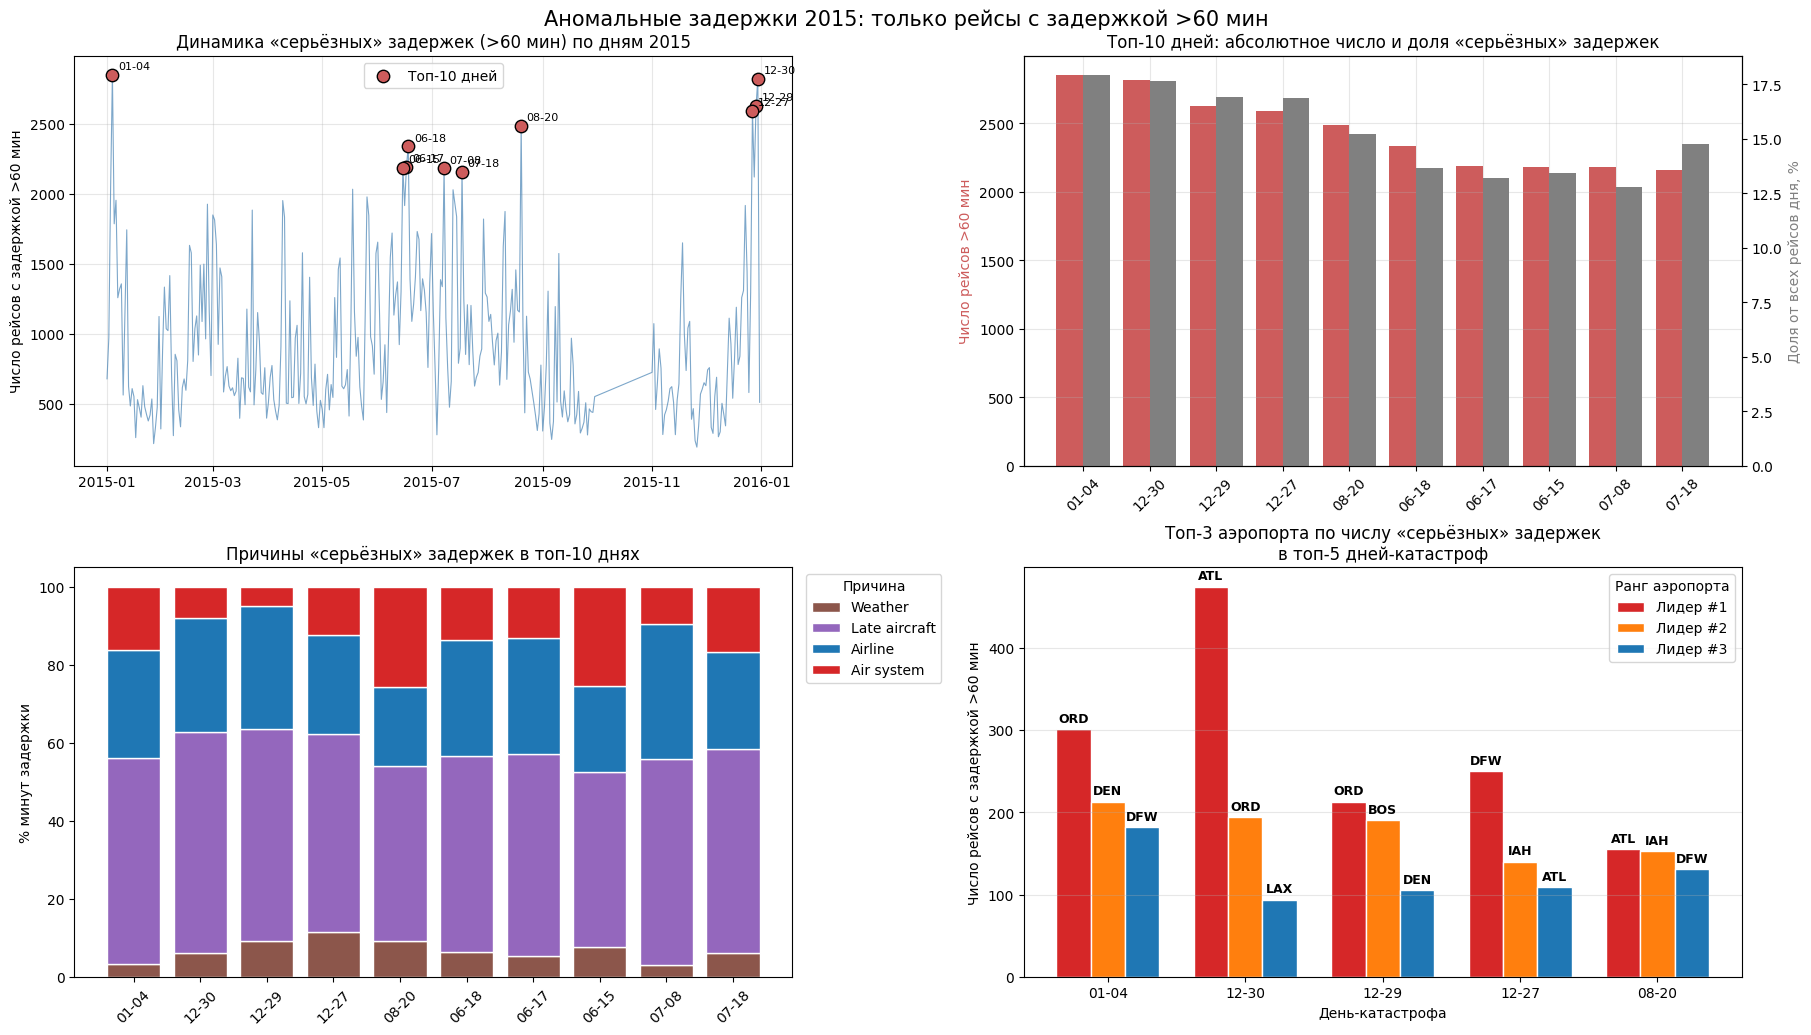

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- 0. Загрузка, если нужно ----
if 'flights' not in globals():
    import kagglehub
    path = kagglehub.dataset_download("usdot/flight-delays")
    usecols = ['YEAR','MONTH','DAY','AIRLINE','ORIGIN_AIRPORT','DESTINATION_AIRPORT',
               'SCHEDULED_DEPARTURE','DEPARTURE_DELAY','ARRIVAL_DELAY','CANCELLED',
               'CANCELLATION_REASON','DIVERTED',
               'AIR_SYSTEM_DELAY','SECURITY_DELAY','AIRLINE_DELAY',
               'LATE_AIRCRAFT_DELAY','WEATHER_DELAY']
    flights = pd.read_csv(os.path.join(path, "flights.csv"),
                          usecols=usecols, low_memory=False)
    print("Загружено:", flights.shape)

if 'airports' not in globals():
    airports = pd.read_csv(os.path.join(path, "airports.csv"))

# ---- 1. Дата ----
flights['date'] = pd.to_datetime(flights[['YEAR','MONTH','DAY']]
                                 .rename(columns={'YEAR':'year','MONTH':'month','DAY':'day'}))

# ---- 2. ФИЛЬТР: только рейсы с задержкой > 60 мин ----
f_big = flights[(flights['CANCELLED'] == 0) &
                (flights['DEPARTURE_DELAY'] > 60)].copy()

print(f"Рейсов с задержкой >60 мин: {len(f_big):,} "
      f"({100*len(f_big)/len(flights[flights['CANCELLED']==0]):.2f}% от всех неотменённых)")

# ---- 3. Сводка по дням ----
daily_big = f_big.groupby('date').agg(
    n_big_delays  = ('DEPARTURE_DELAY', 'size'),
    mean_delay    = ('DEPARTURE_DELAY', 'mean'),
    median_delay  = ('DEPARTURE_DELAY', 'median'),
    max_delay     = ('DEPARTURE_DELAY', 'max'),
    weather_sum   = ('WEATHER_DELAY', 'sum'),
    late_ac_sum   = ('LATE_AIRCRAFT_DELAY', 'sum'),
    airline_sum   = ('AIRLINE_DELAY', 'sum'),
    air_sys_sum   = ('AIR_SYSTEM_DELAY', 'sum'),
)
all_per_day = flights[flights['CANCELLED'] == 0].groupby('date').size().rename('n_all')
daily_big = daily_big.join(all_per_day)
daily_big['share_big_pct'] = daily_big['n_big_delays'] / daily_big['n_all'] * 100

# ---- 4. Топ-10 и топ-5 дней ----
top10 = daily_big.nlargest(10, 'n_big_delays')
top5  = daily_big.nlargest(5, 'n_big_delays')   # для новой диаграммы

# ---- 5. Причины в топ-10 ----
cause_cols_sum = ['weather_sum','late_ac_sum','airline_sum','air_sys_sum']
top10_causes = top10[cause_cols_sum].copy()
top10_causes_pct = top10_causes.div(top10_causes.sum(axis=1), axis=0) * 100

# ---- 6. Аэропорты-лидеры в топ-5 дней ----
# Для каждого из 5 дней берём 3 аэропорта с максимальным числом рейсов >60 мин
top5_airports = {}   # {date: [(iata, n_big), ...3]}
for d in top5.index:
    day_data = f_big[f_big['date'] == d]
    by_ap = (day_data.groupby('ORIGIN_AIRPORT').size()
             .nlargest(3))
    top5_airports[d] = list(by_ap.items())

# Печатаем таблицу для проверки
print("\n=== ТОП-3 АЭРОПОРТА ПО ЧИСЛУ РЕЙСОВ >60 МИН В КАЖДЫЙ ИЗ ТОП-5 ДНЕЙ ===")
for d, aps in top5_airports.items():
    s = ', '.join(f"{ap}({n})" for ap, n in aps)
    print(f"  {d.date()}: {s}")

# ---- 7. Визуализация ----
fig, axes = plt.subplots(2, 2, figsize=(18, 10), constrained_layout=True)

# 7a. Число «серьёзных» задержек по дням с выделенными топ-10
ax = axes[0, 0]
ax.plot(daily_big.index, daily_big['n_big_delays'], color='steelblue',
        linewidth=0.8, alpha=0.7)
ax.scatter(top10.index, top10['n_big_delays'], color='indianred', s=80,
           zorder=3, edgecolor='black', label='Топ-10 дней')
for d, v in top10['n_big_delays'].items():
    ax.annotate(d.strftime('%m-%d'), (d, v), fontsize=8,
                xytext=(4, 4), textcoords='offset points')
ax.set_ylabel('Число рейсов с задержкой >60 мин')
ax.set_title('Динамика «серьёзных» задержек (>60 мин) по дням 2015')
ax.legend()
ax.grid(alpha=0.3)

# 7b. Топ-10: число задержек vs доля от всех рейсов дня
ax = axes[0, 1]
x = np.arange(len(top10))
ax.bar(x - 0.2, top10['n_big_delays'], 0.4,
       label='Число >60 мин', color='indianred')
ax2b = ax.twinx()
ax2b.bar(x + 0.2, top10['share_big_pct'], 0.4,
         label='Доля от рейсов дня, %', color='gray')
ax.set_xticks(x)
ax.set_xticklabels([d.strftime('%m-%d') for d in top10.index], rotation=45)
ax.set_ylabel('Число рейсов >60 мин', color='indianred')
ax2b.set_ylabel('Доля от всех рейсов дня, %', color='gray')
ax.set_title('Топ-10 дней: абсолютное число и доля «серьёзных» задержек')
ax.grid(alpha=0.3)

# 7c. Структура причин в топ-10 (stacked bar)
ax = axes[1, 0]
labels = ['Weather','Late aircraft','Airline','Air system']
colors = ['#8c564b','#9467bd','#1f77b4','#d62728']
bottom = np.zeros(len(top10))
for col, lab, colr in zip(cause_cols_sum, labels, colors):
    ax.bar([d.strftime('%m-%d') for d in top10.index],
           top10_causes_pct[col].values, bottom=bottom,
           label=lab, color=colr, edgecolor='white')
    bottom += top10_causes_pct[col].values
ax.set_ylabel('% минут задержки')
ax.set_title('Причины «серьёзных» задержек в топ-10 днях')
ax.set_xticklabels([d.strftime('%m-%d') for d in top10.index], rotation=45)
ax.legend(title='Причина', bbox_to_anchor=(1.01, 1), loc='upper left')

# 7d. НОВОЕ: топ-3 аэропорта в топ-5 дней-катастроф (grouped bar)
ax = axes[1, 1]
day_labels = [d.strftime('%m-%d') for d in top5.index]
x = np.arange(len(day_labels))
bar_width = 0.25
# Три «позиции» (1-й, 2-й, 3-й аэропорт) — три цвета
rank_colors = ['#d62728', '#ff7f0e', '#1f77b4']
rank_labels = ['Лидер #1', 'Лидер #2', 'Лидер #3']

# Собираем данные: для каждого дня и ранга — (iata, n)
for rank in range(3):
    heights = []
    labels_ap = []
    for d in top5.index:
        aps = top5_airports[d]
        if rank < len(aps):
            ap, n = aps[rank]
            heights.append(n)
            labels_ap.append(ap)
        else:
            heights.append(0)
            labels_ap.append('')
    bars = ax.bar(x + (rank - 1) * bar_width, heights, bar_width,
                  color=rank_colors[rank], label=rank_labels[rank],
                  edgecolor='white')
    # Подписи IATA-кодов над столбцами
    for i, (b, lab, h) in enumerate(zip(bars, labels_ap, heights)):
        if h > 0:
            ax.text(b.get_x() + b.get_width()/2, h + 5, lab,
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(day_labels)
ax.set_xlabel('День-катастрофа')
ax.set_ylabel('Число рейсов с задержкой >60 мин')
ax.set_title('Топ-3 аэропорта по числу «серьёзных» задержек\nв топ-5 дней-катастроф')
ax.legend(title='Ранг аэропорта', loc='upper right')
ax.grid(alpha=0.3, axis='y')

plt.suptitle('Аномальные задержки 2015: только рейсы с задержкой >60 мин', fontsize=15, y=1.02)
plt.show()


Анализируя в течение года **количество задержек >1 часа, видим чёткие пики на днях с погодными аномалиями**, например, 27-30 декабря 2015г. по америке прошёлся Winter Storm Goliath. Сначала рейсы задерживаются из-за погоды (часто повышенный процент Weather), затем аэропорты не могут вовремя облужить скопившееся количество рейсов => большая доля "Late Aircraft".
В такие дни доля долгих задержек составляет 13-17% (в 3-5 раз больше нормального показателя). Аэропорты не готовы к таким форс-мажорам.
Возможные рекомендации: точно зная, что будет климатическая катастрофа, авиалиниям стоит перераспределять потоки в другие аэропорты, заранее информировать пассажиров. Аэропорты должны быть лучше готовы к форс-мажорам, так, например, южные аэропорты часто не готовы к работе в обильные снегопады (как 27-30.12.2015, 04.01.2015 что видно из последней диаграммы), хотя эти эпизоды происходят постоянно ("никогда такого не было и вот опять").

# *) Сравним задержку в аэропортах республиканских и демократических штатов (несерьёзное сравнение)

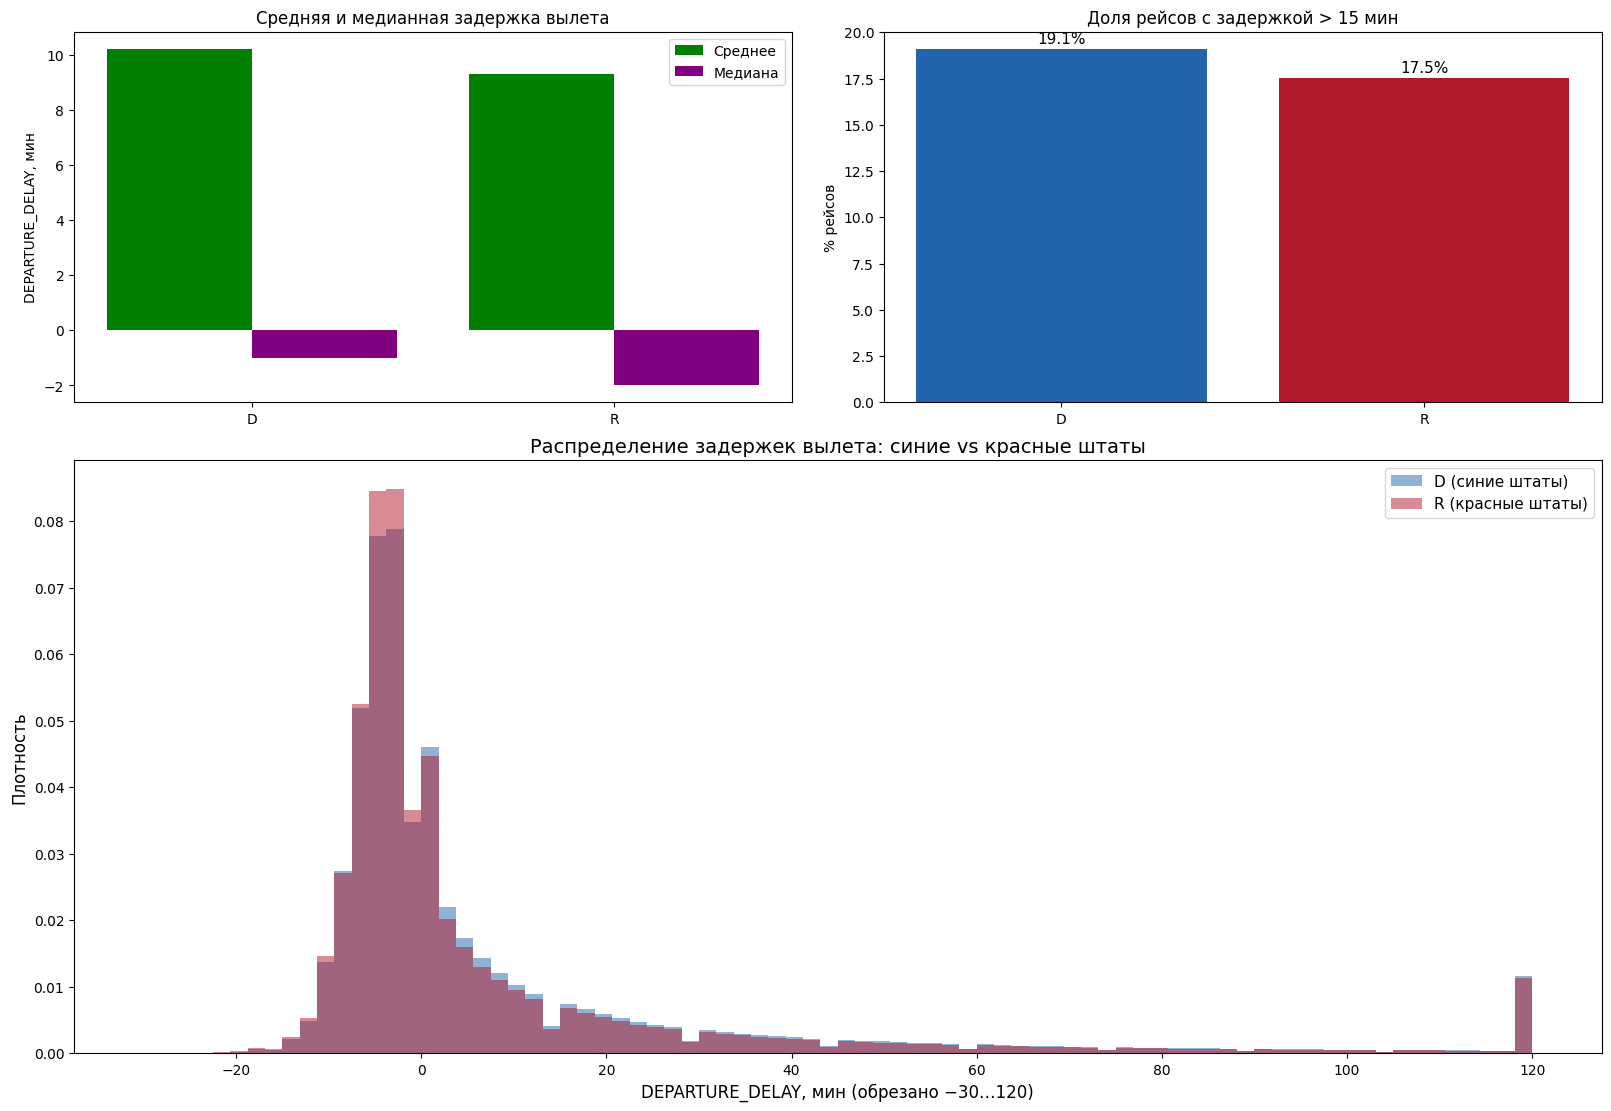

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ---- 1. Политическая принадлежность штатов (выборы 2016) ----
state_party_2016 = {
    'CA':'D','CO':'D','CT':'D','DE':'D','DC':'D','HI':'D','IL':'D','ME':'D',
    'MD':'D','MA':'D','MN':'D','NV':'D','NH':'D','NJ':'D','NM':'D','NY':'D',
    'OR':'D','RI':'D','VT':'D','VA':'D','WA':'D',
    'AL':'R','AK':'R','AZ':'R','AR':'R','FL':'R','GA':'R','ID':'R','IN':'R',
    'IA':'R','KS':'R','KY':'R','LA':'R','MI':'R','MS':'R','MO':'R','MT':'R',
    'NE':'R','NC':'R','ND':'R','OH':'R','OK':'R','PA':'R','SC':'R','SD':'R',
    'TN':'R','TX':'R','UT':'R','WV':'R','WI':'R','WY':'R',
}

# ---- 2. Присоединяем партию к рейсам через аэропорт вылета ----
origin_party = airports[['IATA_CODE', 'STATE']].rename(
    columns={'IATA_CODE': 'ORIGIN_AIRPORT', 'STATE': 'origin_state'})
origin_party['party'] = origin_party['origin_state'].map(state_party_2016)

f = flights.merge(origin_party[['ORIGIN_AIRPORT', 'origin_state', 'party']],
                  on='ORIGIN_AIRPORT', how='left')

f = f[(f['CANCELLED'] == 0) & f['DEPARTURE_DELAY'].notna() & f['party'].notna()]

# ---- 3. Метрики ----
means   = f.groupby('party')['DEPARTURE_DELAY'].mean()
medians = f.groupby('party')['DEPARTURE_DELAY'].median()
share15 = (f.assign(is_delayed=f['DEPARTURE_DELAY'] > 15)
           .groupby('party')['is_delayed'].mean() * 100)

d = f.loc[f['party'] == 'D', 'DEPARTURE_DELAY']
r = f.loc[f['party'] == 'R', 'DEPARTURE_DELAY']

# ---- 4. Визуализация: 2 графика сверху, крупный снизу ----
fig = plt.figure(figsize=(16, 11), constrained_layout=True)
gs = GridSpec(2, 2, figure=fig, height_ratios=[1, 1.6])

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])   # во всю ширину, крупнее

# 4a. Среднее и медиана
x = np.arange(len(means))
ax1.bar(x - 0.2, means.values,   width=0.4, label='Среднее', color='green')
ax1.bar(x + 0.2, medians.values, width=0.4, label='Медиана', color='purple')
ax1.set_xticks(x); ax1.set_xticklabels(means.index)
ax1.set_ylabel('DEPARTURE_DELAY, мин')
ax1.set_title('Средняя и медианная задержка вылета')
ax1.legend()

# 4b. Доля задержанных > 15 мин
ax2.bar(share15.index, share15.values, color=['#2166ac', '#b2182b'])
ax2.set_ylabel('% рейсов')
ax2.set_title('Доля рейсов с задержкой > 15 мин')
for i, v in enumerate(share15.values):
    ax2.text(i, v + 0.3, f'{v:.1f}%', ha='center', fontsize=11)

# 4c. Крупное распределение задержек
ax3.hist(d.clip(-30, 120), bins=80, density=True, alpha=0.5,
         label='D (синие штаты)', color='#2166ac')
ax3.hist(r.clip(-30, 120), bins=80, density=True, alpha=0.5,
         label='R (красные штаты)', color='#b2182b')
ax3.set_xlabel('DEPARTURE_DELAY, мин (обрезано −30…120)', fontsize=12)
ax3.set_ylabel('Плотность', fontsize=12)
ax3.set_title('Распределение задержек вылета: синие vs красные штаты',
              fontsize=14)
ax3.legend(fontsize=11)

plt.show()

Вывод: Аэропорты и авиакампании **в республиканских штатах** справляются со своей работой немного **лучше!**

*Make Air Travel Great Again!*

(В реальности понятно, что это вызвано некой спецификой работы аэропортов в разных штатах, например, в демократических больше крупных и загруженных хабов, разной структурой трафика и погодными условиями в штатах, а сама разница почти незаметна)